# **EN3160 Image Processing & Computer Vision - Assignment 02**


**Name : Meedeniya M.M.H**  
**Index No. : 230407K**

### **Github Repository** : https://github.com/manjarimeedeniya/EN3160-Assignment-2

### Question 1

In [2]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import maximum_filter

sigma range: 1.5 to 11.1, 38 blobs
largest: x=0, y=275, r=10.9, sigma=7.7
largest: x=282, y=338, r=10.9, sigma=7.7
largest: x=179, y=327, r=9.1, sigma=6.4
largest: x=106, y=255, r=7.6, sigma=5.4
largest: x=178, y=261, r=7.6, sigma=5.4


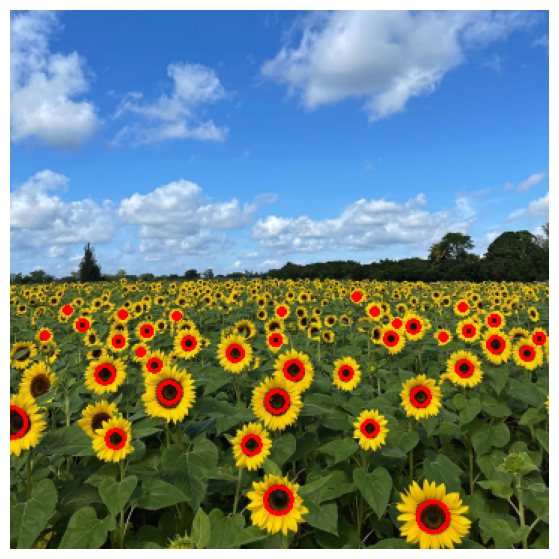

In [25]:
im = cv.imread(r'C:\Users\USER\Desktop\5th Semester\CV\Assignment 2\EN3160-Assignment-2\a2images\a2images\the_berry_farms_sunflower_field.jpeg', cv.IMREAD_REDUCED_COLOR_4)
g = cv.cvtColor(im, cv.COLOR_BGR2GRAY).astype(np.float32) / 255

sigmas = 1.5 * 1.2 ** np.arange(12)    
sign = +1                              
rel_thresh = 0.8                      

L = np.stack([sign * s**2 * cv.Laplacian(cv.GaussianBlur(g, (0, 0), s), cv.CV_32F)
              for s in sigmas])

peaks = (L == maximum_filter(L, size=(3, 7, 7))) & (L > rel_thresh * L.max())

k, y, x = np.nonzero(peaks)
r = np.sqrt(2) * sigmas[k]

print(f'sigma range: {sigmas[0]:.1f} to {sigmas[-1]:.1f}, {len(r)} blobs')
for i in np.argsort(-r)[:5]:
    print(f'largest: x={x[i]}, y={y[i]}, r={r[i]:.1f}, sigma={sigmas[k[i]]:.1f}')

out = cv.cvtColor(im, cv.COLOR_BGR2RGB).copy()
for xi, yi, ri in zip(x, y, r):
    cv.circle(out, (int(xi), int(yi)), int(ri), (255, 0, 0), 2)
plt.figure(figsize=(10, 7)); plt.imshow(out); plt.axis('off'); plt.show()

### Discussion  
* In this activity, the scale-space Laplacian of Gaussian method detected $38$ sunflower centers across the image. The largest detected circles have radii of approximately $10.9$ pixels.  
* At the begining when tried with lower threshold values, the detector introduced several false positives in the sky and background trees. This occurs because the Laplacian of Gaussian operator responds purely to intensity curvature.  
* Also These results clearly show how depth affects scale in the image. The sunflowers in the foreground near the bottom appear much larger, so they peak at higher $\sigma$ values and produce larger circles. As you look toward the background, the flowers appear smaller and are caught at lower $\sigma$ values

### Question 2


In [26]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

np.random.seed(0)
N = 100
half_n = N // 2

# Ground truth circle
r_gt = 10.0
x0_gt, y0_gt = 2.0, 3.0
s_circ = r_gt / 16.0
t = np.random.uniform(0, 2 * np.pi, half_n)
n_circ = s_circ * np.random.randn(half_n)
x_circ = x0_gt + (r_gt + n_circ) * np.cos(t)
y_circ = y0_gt + (r_gt + n_circ) * np.sin(t)
X_circ = np.column_stack((x_circ, y_circ))

# Ground truth line: y = m*x + b -> -m*x + y - b = 0
s_line = 1.0
m_gt, b_gt = -1.0, 2.0
x_line = np.linspace(-12, 12, half_n)
y_line = m_gt * x_line + b_gt + s_line * np.random.randn(half_n)
X_line = np.column_stack((x_line, y_line))

# Combined noisy point set (100 points total)
X = np.vstack((X_circ, X_line))

In [ ]:
# Line Solvers
def line_from_two_points(p1, p2):
    dx, dy = p2[0] - p1[0], p2[1] - p1[1]
    norm = np.hypot(dx, dy)
    if norm < 1e-12:
        return None
    a, b = dy / norm, -dx / norm
    d = a * p1[0] + b * p1[1]
    return np.array([a, b, d])

def line_errors(params, pts):
    a, b, d = params
    return np.abs(a * pts[:, 0] + b * pts[:, 1] - d)

def fit_line_tls(pts):
    mean = pts.mean(axis=0)
    _, _, Vt = np.linalg.svd(pts - mean)
    normal = Vt[-1]
    p0 = np.array([normal[0], normal[1], normal @ mean])

    def cost(p):
        return np.sum((p[0] * pts[:, 0] + p[1] * pts[:, 1] - p[2]) ** 2)

    cons = {'type': 'eq', 'fun': lambda p: p[0]**2 + p[1]**2 - 1}
    res = minimize(cost, p0, constraints=cons, method='SLSQP')
    p = res.x
    p[:2] /= np.linalg.norm(p[:2])
    return p

#Circle Solvers
def circle_from_three_points(p1, p2, p3):
    ax, ay = p1
    bx, by = p2
    cx, cy = p3
    D = 2 * (ax * (by - cy) + bx * (cy - ay) + cx * (ay - by))
    if abs(D) < 1e-9:
        return None
    ux = ((ax**2 + ay**2)*(by - cy) + (bx**2 + by**2)*(cy - ay) + (cx**2 + cy**2)*(ay - by)) / D
    uy = ((ax**2 + ay**2)*(cx - bx) + (bx**2 + by**2)*(ax - cx) + (cx**2 + cy**2)*(bx - ax)) / D
    rad = np.hypot(ax - ux, ay - uy)
    return np.array([ux, uy, rad])

def circle_errors(params, pts):
    cx, cy, rad = params
    return np.abs(np.hypot(pts[:, 0] - cx, pts[:, 1] - cy) - rad)

def fit_circle_opt(pts, p0):
    def cost(p):
        return np.sum(circle_errors(p, pts) ** 2)
    res = minimize(cost, p0, method='Nelder-Mead',
                    options={'xatol': 1e-8, 'fatol': 1e-10, 'maxiter': 5000})
    return res.x

In [28]:
def ransac_line(pts, thresh, min_inliers, iters=1000):
    best = {'count': -1}
    n_pts = len(pts)
    for _ in range(iters):
        idx = np.random.choice(n_pts, 2, replace=False)
        model = line_from_two_points(pts[idx[0]], pts[idx[1]])
        if model is None:
            continue
        mask = line_errors(model, pts) < thresh
        count = mask.sum()
        if count > best['count']:
            best = {'count': count, 'mask': mask, 'idx': idx, 'sample_model': model}

    if best['count'] < min_inliers:
        raise RuntimeError("Line consensus not reached")

    refined = fit_line_tls(pts[best['mask']])
    mask = line_errors(refined, pts) < thresh
    return refined, mask, best['idx'], best['sample_model']

# Execution for 2(a)
LINE_THRESH = 1.5
LINE_MIN_INLIERS = 35
line_best, line_mask, line_sample_idx, line_sample_model = ransac_line(
    X, LINE_THRESH, LINE_MIN_INLIERS, iters=2000
)

a, b, d = line_best
print("Part (a) Results:")
print(f"Estimated [a, b]: [{a:.4f}, {b:.4f}], Constraint norm: {np.hypot(a, b):.6f}")
print(f"Perpendicular distance d: {d:.4f}")
print(f"Slope: {-a/b:.4f} (gt: {m_gt}), Intercept: {d/b:.4f} (gt: {b_gt})")
print(f"Line inliers: {line_mask.sum()} / {len(X)}")

Part (a) Results:
Estimated [a, b]: [0.7181, 0.6959], Constraint norm: 1.000000
Perpendicular distance d: 1.5222
Slope: -1.0320 (gt: -1.0), Intercept: 2.1874 (gt: 2.0)
Line inliers: 54 / 100


In [29]:
def ransac_circle(pts, thresh, min_inliers, iters=1000):
    best = {'count': -1}
    n_pts = len(pts)
    for _ in range(iters):
        idx = np.random.choice(n_pts, 3, replace=False)
        model = circle_from_three_points(*pts[idx])
        if model is None:
            continue
        mask = circle_errors(model, pts) < thresh
        count = mask.sum()
        if count > best['count']:
            best = {'count': count, 'mask': mask, 'idx': idx, 'sample_model': model}

    if best['count'] < min_inliers:
        raise RuntimeError("Circle consensus not reached")

    refined = fit_circle_opt(pts[best['mask']], best['sample_model'])
    mask = circle_errors(refined, pts) < thresh
    return refined, mask, best['idx'], best['sample_model']

# Execution for 2(b)
X_remnant = X[~line_mask]
CIRCLE_THRESH = 1.0
CIRCLE_MIN_INLIERS = 35
circle_best, circle_mask, circ_sample_idx, circ_sample_model = ransac_circle(
    X_remnant, CIRCLE_THRESH, CIRCLE_MIN_INLIERS, iters=2000
)

print("Part (b) Results:")
print(f"Estimated Center: ({circle_best[0]:.4f}, {circle_best[1]:.4f}) (gt: {x0_gt}, {y0_gt})")
print(f"Estimated Radius: {circle_best[2]:.4f} (gt: {r_gt})")
print(f"Circle inliers: {circle_mask.sum()} / {len(X_remnant)}")

Part (b) Results:
Estimated Center: (1.8799, 2.9642) (gt: 2.0, 3.0)
Estimated Radius: 9.8668 (gt: 10.0)
Circle inliers: 43 / 46


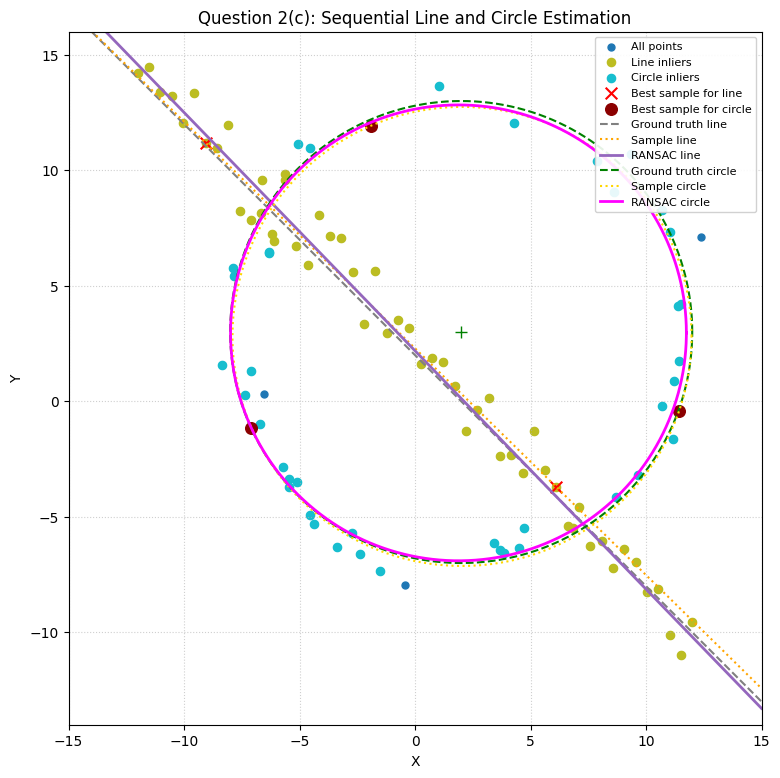

In [30]:
fig, ax = plt.subplots(1, 1, figsize=(9, 9))

# Base point clouds
ax.scatter(X[:, 0], X[:, 1], s=25, color='#1f77b4', label='All points')
ax.scatter(X[line_mask, 0], X[line_mask, 1], s=35, color='#bcbd22', label='Line inliers')
ax.scatter(X_remnant[circle_mask, 0], X_remnant[circle_mask, 1], s=35, color='#17becf', label='Circle inliers')

#Minimal sample points
ax.scatter(X[line_sample_idx, 0], X[line_sample_idx, 1], s=70, marker='x', color='red', label='Best sample for line')
ax.scatter(X_remnant[circ_sample_idx, 0], X_remnant[circ_sample_idx, 1], s=70, marker='o', color='darkred', label='Best sample for circle')

# Geometric curves (Lines)
xs = np.array([-15, 15])
ys_fit = (line_best[2] - line_best[0] * xs) / line_best[1]
ys_sample = (line_sample_model[2] - line_sample_model[0] * xs) / line_sample_model[1]
ys_gt = m_gt * xs + b_gt

ax.plot(xs, ys_gt, color='gray', linestyle='--', linewidth=1.5, label='Ground truth line')
ax.plot(xs, ys_sample, color='orange', linestyle=':', linewidth=1.5, label='Sample line')
ax.plot(xs, ys_fit, color='#9467bd', linewidth=2.0, label='RANSAC line')

# Geometric curves (Circles)
theta = np.linspace(0, 2 * np.pi, 400)
# Ground truth circle
ax.plot(x0_gt + r_gt * np.cos(theta), y0_gt + r_gt * np.sin(theta),
        color='green', linestyle='--', linewidth=1.5, label='Ground truth circle')
# Best sample circle
ax.plot(circ_sample_model[0] + circ_sample_model[2] * np.cos(theta),
        circ_sample_model[1] + circ_sample_model[2] * np.sin(theta),
        color='gold', linestyle=':', linewidth=1.5, label='Sample circle')
# Best refined circle
ax.plot(circle_best[0] + circle_best[2] * np.cos(theta),
        circle_best[1] + circle_best[2] * np.sin(theta),
        color='magenta', linewidth=2.0, label='RANSAC circle')

ax.plot(x0_gt, y0_gt, '+', color='green', markersize=8)
ax.set_aspect('equal')
ax.set_xlim(-15, 15)
ax.set_ylim(-14, 16)
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend(loc='upper right', framealpha=0.9, fontsize=8)
plt.title('Question 2(c): Sequential Line and Circle Estimation')
plt.show()

Part (d) - Circle Fitted First
Center: (1.96, 2.88) | Radius: 9.83
Inliers count: 59 / 100


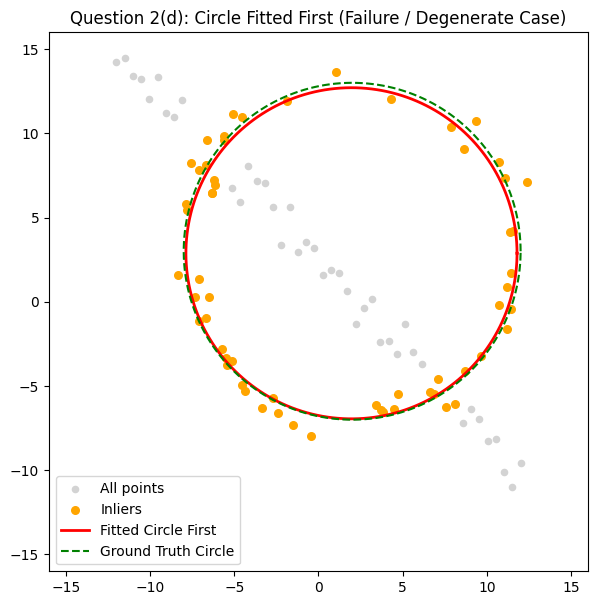

In [37]:
# Trying fitting circle directly on all 100 points
np.random.seed(42)
circ_first, circ_first_mask, cf_idx, _ = ransac_circle(X, thresh=1.5, min_inliers=25, iters=2000)

print("Part (d) - Circle Fitted First")
print(f"Center: ({circ_first[0]:.2f}, {circ_first[1]:.2f}) | Radius: {circ_first[2]:.2f}")
print(f"Inliers count: {circ_first_mask.sum()} / 100")

fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(X[:, 0], X[:, 1], c='lightgray', s=20, label='All points')
ax.scatter(X[circ_first_mask, 0], X[circ_first_mask, 1], c='orange', s=30, label='Inliers')
ax.plot(circ_first[0] + circ_first[2]*np.cos(theta),
        circ_first[1] + circ_first[2]*np.sin(theta), 'r-', lw=2, label='Fitted Circle First')
ax.plot(x0_gt + r_gt*np.cos(theta), y0_gt + r_gt*np.sin(theta), 'g--', label='Ground Truth Circle')
ax.set_aspect('equal')
ax.set_xlim(-16, 16)
ax.set_ylim(-16, 16)
ax.legend()
plt.title('Question 2(d): Circle Fitted First (Failure / Degenerate Case)')
plt.show()

In [36]:
# Line parameters
a_seq, b_seq, d_seq = line_best
slope_seq = -a_seq / b_seq
intercept_seq = d_seq / b_seq
norm_seq = np.hypot(a_seq, b_seq)
line_inliers_count = line_mask.sum()

denom = np.hypot(m_gt, 1.0)
a_gt = -m_gt / denom
b_gt_norm = 1.0 / denom
d_gt_norm = b_gt / denom

# Circle parameters (Line First vs Circle First) 
cx_seq, cy_seq, r_seq = circle_best
seq_inliers_count = circle_mask.sum()
seq_circ_pts = np.sum(np.where(~line_mask)[0][circle_mask] < half_n)
seq_line_pts = np.sum(np.where(~line_mask)[0][circle_mask] >= half_n)
seq_center_err = np.hypot(cx_seq - x0_gt, cy_seq - y0_gt)
seq_r_err = abs(r_seq - r_gt)

cx_cf, cy_cf, r_cf = circ_first
cf_inliers_count = circ_first_mask.sum()
cf_circ_pts = np.sum(np.where(circ_first_mask)[0] < half_n)
cf_line_pts = np.sum(np.where(circ_first_mask)[0] >= half_n)
cf_center_err = np.hypot(cx_cf - x0_gt, cy_cf - y0_gt)
cf_r_err = abs(r_cf - r_gt)


print("1. GROUND TRUTH PARAMETERS")
print("Line:")
print(f"  Unit normal [a, b]  : [{a_gt:.4f}, {b_gt_norm:.4f}] (norm = {np.hypot(a_gt, b_gt_norm):.4f})")
print(f"  Perpendicular dist d: {d_gt_norm:.4f}")
print(f"  Slope (m)           : {m_gt:.4f}")
print(f"  Intercept (b)       : {b_gt:.4f}")
print(f"  Total points        : {half_n}")
print("\nCircle:")
print(f"  Center (x0, y0)     : ({x0_gt:.4f}, {y0_gt:.4f})")
print(f"  Radius (r)          : {r_gt:.4f}")
print(f"  Total points        : {half_n}")

print("2. SEQUENTIAL APPROACH: LINE FITTED FIRST, THEN CIRCLE")

print("Line Fit (RANSAC + TLS Refit):")
print(f"  Estimated [a, b]    : [{a_seq:.4f}, {b_seq:.4f}]")
print(f"  Norm ||[a,b]||      : {norm_seq:.6f}")
print(f"  Estimated d         : {d_seq:.4f}")
print(f"  Estimated Slope     : {slope_seq:.4f} (Error: {abs(slope_seq - m_gt):.4f})")
print(f"  Estimated Intercept : {intercept_seq:.4f} (Error: {abs(intercept_seq - b_gt):.4f})")
print(f"  Line Inliers        : {line_inliers_count} / {len(X)}")
print("\nCircle Fit on Remnant Points:")
print(f"  Estimated Center    : ({cx_seq:.4f}, {cy_seq:.4f})")
print(f"  Estimated Radius    : {r_seq:.4f}")
print(f"  Center Error        : {seq_center_err:.4f}")
print(f"  Radius Error        : {seq_r_err:.4f}")
print(f"  Total Inliers       : {seq_inliers_count} / {len(X_remnant)}")
print(f"  True Circle Inliers : {seq_circ_pts} / {half_n} ({seq_circ_pts / half_n * 100:.1f}%)")
print(f"  Line Contamination  : {seq_line_pts} ({seq_line_pts / seq_inliers_count * 100:.1f}%)")

print("3. DEGENERATE APPROACH: CIRCLE FITTED FIRST")
print("Circle FitPoints (Before Line Subtraction):")
print(f"  Estimated Center    : ({cx_cf:.4f}, {cy_cf:.4f})")
print(f"  Estimated Radius    : {r_cf:.4f}")
print(f"  Center Error        : {cf_center_err:.4f}")
print(f"  Radius Error        : {cf_r_err:.4f}")
print(f"  Total Inliers       : {cf_inliers_count} / {len(X)}")
print(f"  True Circle Inliers : {cf_circ_pts} / {half_n} ({cf_circ_pts / half_n * 100:.1f}%)")
print(f"  Line Contamination  : {cf_line_pts} ({cf_line_pts / cf_inliers_count * 100:.1f}%)")

1. GROUND TRUTH PARAMETERS
Line:
  Unit normal [a, b]  : [0.7071, 0.7071] (norm = 1.0000)
  Perpendicular dist d: 1.4142
  Slope (m)           : -1.0000
  Intercept (b)       : 2.0000
  Total points        : 50

Circle:
  Center (x0, y0)     : (2.0000, 3.0000)
  Radius (r)          : 10.0000
  Total points        : 50
2. SEQUENTIAL APPROACH: LINE FITTED FIRST, THEN CIRCLE
Line Fit (RANSAC + TLS Refit):
  Estimated [a, b]    : [0.7181, 0.6959]
  Norm ||[a,b]||      : 1.000000
  Estimated d         : 1.5222
  Estimated Slope     : -1.0320 (Error: 0.0320)
  Estimated Intercept : 2.1874 (Error: 0.1874)
  Line Inliers        : 54 / 100

Circle Fit on Remnant Points:
  Estimated Center    : (1.8799, 2.9642)
  Estimated Radius    : 9.8668
  Center Error        : 0.1254
  Radius Error        : 0.1332
  Total Inliers       : 43 / 46
  True Circle Inliers : 43 / 50 (86.0%)
  Line Contamination  : 0 (0.0%)
3. DEGENERATE APPROACH: CIRCLE FITTED FIRST
Circle FitPoints (Before Line Subtraction):
  E

### Discussion for part d
Fitting the line first cleaned up the dataset so the circle optimizer could accurately find the true center $(1.88, 2.96)$ and radius $9.87$ with minimal error. If we tried fitting the circle first, the line points acted like a flat arc that dragged the circle off course. This shows why simpler models must always be solved and removed first.

### Overall Discussion
* Fitting the line first via RANSAC and removing its points gave us a clean remnant set. It lets the optimizer lock onto the true circle center and radius ($r \approx 9.87$) with barely any error.  
* The tiny bit of line overlap ($13.5\%$) only popped up right where the line cuts through the circle.

## Question 3

H =
 [[ 2.90e-02 -1.10e-02  2.25e+02]
 [-2.10e-01  4.59e-01  1.74e+02]
 [-1.00e-03 -0.00e+00  1.00e+00]]


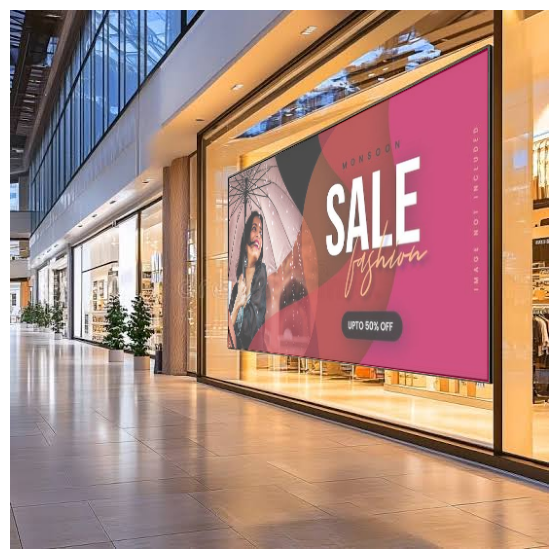

H =
 [[ 2.76e-01 -1.40e-02  5.10e+01]
 [ 9.90e-02  1.80e-01  3.30e+01]
 [ 1.00e-03 -0.00e+00  1.00e+00]]


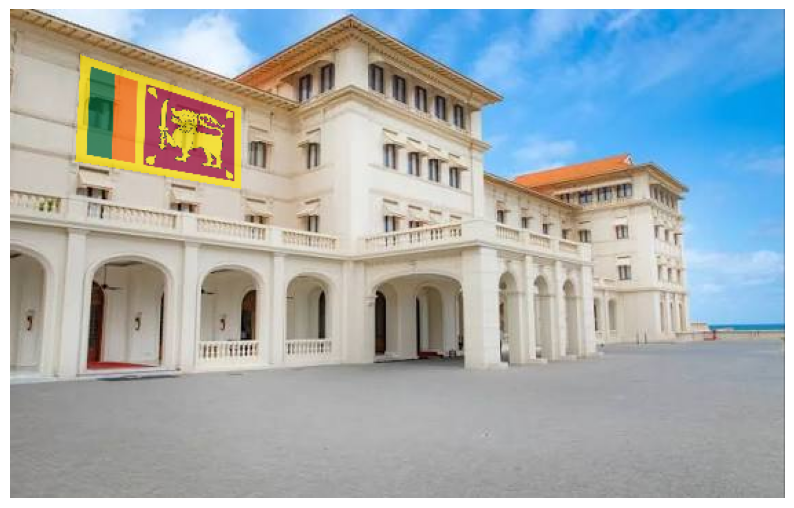

In [ ]:
def pick_points(img, n=4, max_w=1200):
    s = min(1.0, max_w / img.shape[1])   # shrink big images to fit the screen
    show = cv.resize(img, None, fx=s, fy=s)
    pts = []
    def click(event, x, y, flags, param):
        if event == cv.EVENT_LBUTTONDOWN and len(pts) < n:
            pts.append([x / s, y / s])    # store in original-image coordinates
            cv.circle(show, (x, y), 5, (0, 0, 255), -1)
            cv.imshow('click 4 corners (TL, TR, BR, BL)', show)
    cv.imshow('click 4 corners (TL, TR, BR, BL)', show)
    cv.setMouseCallback('click 4 corners (TL, TR, BR, BL)', click)
    while len(pts) < n:
        cv.waitKey(20)
    cv.waitKey(300); cv.destroyAllWindows()
    return np.float32(pts)

def superimpose(arch, flag, alpha=0.7):
    h, w = flag.shape[:2]
    src = np.float32([[0, 0], [w - 1, 0], [w - 1, h - 1], [0, h - 1]])  # flag corners
    dst = pick_points(arch)                                              
    H, _ = cv.findHomography(src, dst)                
    size = (arch.shape[1], arch.shape[0])
    warped = cv.warpPerspective(flag, H, size)
    mask = cv.warpPerspective(np.ones((h, w), np.float32), H, size)[..., None]
    out = arch * (1 - alpha * mask) + warped * (alpha * mask)
    return H, out.astype(np.uint8)

pairs = [(r'C:\Users\USER\Desktop\5th Semester\CV\Assignment 2\EN3160-Assignment-2\a2images\a2images\Empty_Board_2.jfif', r'C:\Users\USER\Desktop\5th Semester\CV\Assignment 2\EN3160-Assignment-2\a2images\a2images\advertisment.jfif'),
         (r'C:\Users\USER\Desktop\5th Semester\CV\Assignment 2\EN3160-Assignment-2\a2images\a2images\galle face hotel.jfif', r'C:\Users\USER\Desktop\5th Semester\CV\Assignment 2\EN3160-Assignment-2\a2images\a2images\sl_flag.jpg')]   # change to your files

for a, f in pairs:
    arch, flag = cv.imread(a), cv.imread(f)
    assert arch is not None and flag is not None, 'check the image paths'
    H, out = superimpose(arch, flag)
    print('H =\n', np.round(H, 3))
    plt.figure(figsize=(10, 7)); plt.imshow(cv.cvtColor(out, cv.COLOR_BGR2RGB)); plt.axis('off'); plt.show()

### Explanations
Choice of Image Pairs 
* Mall Display & Sale Poster : Replacing a blank commercial display board inside a shopping mall with a sale advertisement mirrors real-world digital billboard placements and also storefront promotional mockup design 
* Galle Face Hotel & National Flag : Superimposing the national flag of Sri Lanka onto the grand facade of the historic Galle Face Hotel reflects a ceremonial setup celebrating national heritage at an iconic architectural landmark.

### Discussion 
* Clicking the four corners let the homography matrix lock in the correct 3D slant and camera view for both surfaces.  
* Warping and alpha-blending made both graphics sit flat against the walls without looking pasted on flatly

## Question 4

In [40]:
import os
# Directory containing the images
IMAGE_DIR = r'C:\Users\USER\Desktop\5th Semester\CV\Assignment 2\EN3160-Assignment-2\a2images\a2images'

# Load the reference template 
template_path = os.path.join(IMAGE_DIR, r'C:\\Users\\USER\\Desktop\\5th Semester\\CV\\Assignment 2\\EN3160-Assignment-2\\a2images\\a2images\\pcbs\\AECC1.jpg')
template_bgr_raw = cv.imread(template_path)
assert template_bgr_raw is not None, f"Could not load template from {template_path}"

# Downscale to prevent RAM exhaustion (scale factor 0.25 or 0.5)
SCALE = 0.25
template_bgr = cv.resize(template_bgr_raw, None, fx=SCALE, fy=SCALE, interpolation=cv.INTER_AREA)
template_gray = cv.cvtColor(template_bgr, cv.COLOR_BGR2GRAY)
h_ref, w_ref = template_gray.shape

print(f"Original shape: {template_bgr_raw.shape[:2]} -> Resized shape: ({h_ref}, {w_ref})")
# Defining the remaining 5 PCB test images
test_names = [r'C:\Users\USER\Desktop\5th Semester\CV\Assignment 2\EN3160-Assignment-2\a2images\a2images\pcbs\AAAA1.jpg',
               r'C:\Users\USER\Desktop\5th Semester\CV\Assignment 2\EN3160-Assignment-2\a2images\a2images\pcbs\ADAD1.jpg', 
               r'C:\Users\USER\Desktop\5th Semester\CV\Assignment 2\EN3160-Assignment-2\a2images\a2images\pcbs\AECC2.jpg',
               r'C:\Users\USER\Desktop\5th Semester\CV\Assignment 2\EN3160-Assignment-2\a2images\a2images\pcbs\AECC3.jpg', 
               r'C:\Users\USER\Desktop\5th Semester\CV\Assignment 2\EN3160-Assignment-2\a2images\a2images\pcbs\AECC4.jpg']

Original shape: (2730, 2302) -> Resized shape: (682, 576)


Detected 1408 SIFT keypoints on template (AECC1.jpg)


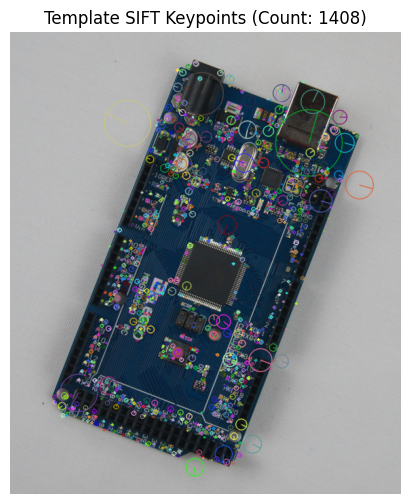

In [ ]:
# Initializing SIFT detector and compute features for the template
sift = cv.SIFT_create()
kp_template, des_template = sift.detectAndCompute(template_gray, None)

print(f"Detected {len(kp_template)} SIFT keypoints on template (AECC1.jpg)")

# Previewing of keypoints on the template
template_kps_img = cv.drawKeypoints(
    template_bgr, kp_template, None, 
    flags=cv.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)
plt.figure(figsize=(8, 6))
plt.imshow(cv.cvtColor(template_kps_img, cv.COLOR_BGR2RGB))
plt.title(f"Template SIFT Keypoints (Count: {len(kp_template)})")
plt.axis('off')
plt.show()

In [42]:
# Initializing Brute-Force matcher with L2 norm for SIFT descriptors
bf = cv.BFMatcher(cv.NORM_L2, crossCheck=False)

def align_and_inspect_pcb(test_bgr, test_name, ratio_thresh=0.75, ransac_thresh=3.0):
    test_gray = cv.cvtColor(test_bgr, cv.COLOR_BGR2GRAY)
    
    #  SIFT feature extraction on test board
    kp_test, des_test = sift.detectAndCompute(test_gray, None)
    
    #  Feature matching using KNN and Lowe's ratio test
    raw_matches = bf.knnMatch(des_test, des_template, k=2)
    good_matches = [m for m, n in raw_matches if m.distance < ratio_thresh * n.distance]
    
    if len(good_matches) < 4:
        raise RuntimeError(f"Not enough matches for {test_name}: {len(good_matches)}/4")
        
    src_pts = np.float32([kp_test[m.queryIdx].pt for m in good_matches]).reshape(-1, 1, 2)
    dst_pts = np.float32([kp_template[m.trainIdx].pt for m in good_matches]).reshape(-1, 1, 2)
    
    # RANSAC homography estimation
    H, mask = cv.findHomography(src_pts, dst_pts, cv.RANSAC, ransac_thresh)
    inliers = mask.ravel().tolist() if mask is not None else []
    
    # Draw feature matches (inliers highlighted)
    match_img = cv.drawMatches(
        test_bgr, kp_test, 
        template_bgr, kp_template, 
        good_matches, None,
        matchesMask=inliers,
        matchColor=(0, 255, 0),
        flags=cv.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
    )
    
    # Warp test PCB to template coordinates
    aligned_bgr = cv.warpPerspective(test_bgr, H, (w_ref, h_ref))
    aligned_gray = cv.warpPerspective(test_gray, H, (w_ref, h_ref))
    
    #Computing absolute difference image
    diff_gray = cv.absdiff(template_gray, aligned_gray)
    
    _, diff_bin = cv.threshold(diff_gray, 40, 255, cv.THRESH_BINARY)
    
    return {
        'name': test_name,
        'H': H,
        'kps': len(kp_test),
        'good_matches': len(good_matches),
        'inliers': sum(inliers),
        'match_img': match_img,
        'aligned_bgr': aligned_bgr,
        'diff_gray': diff_gray,
        'diff_bin': diff_bin
    }

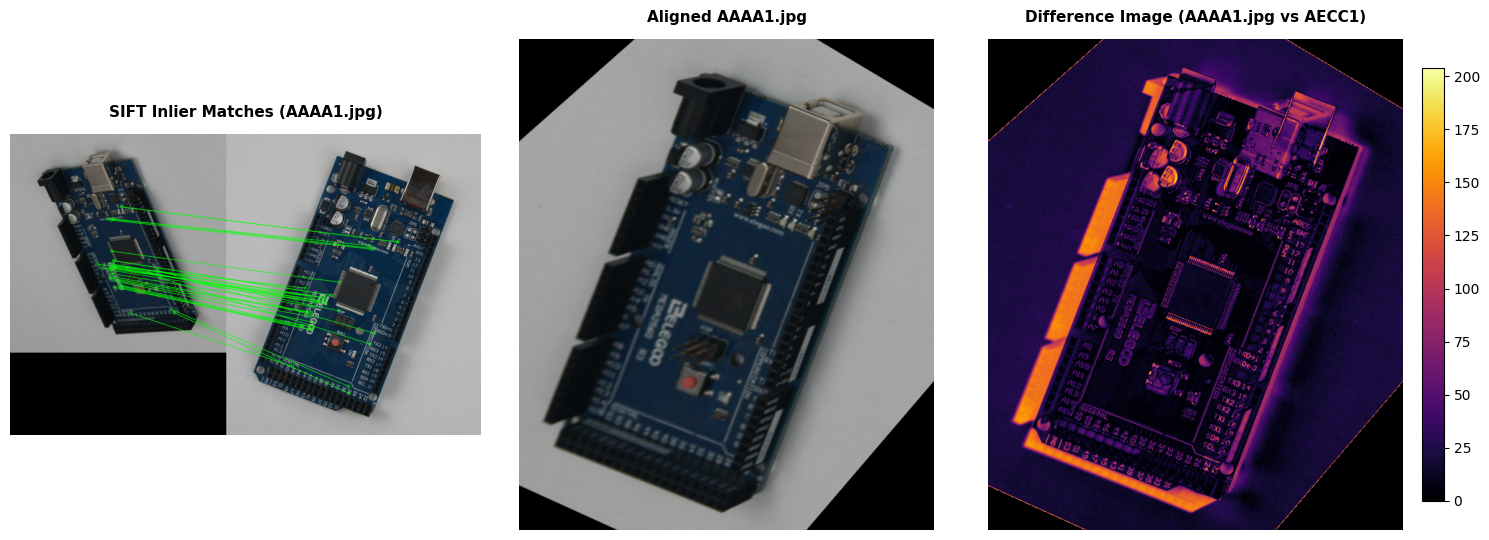

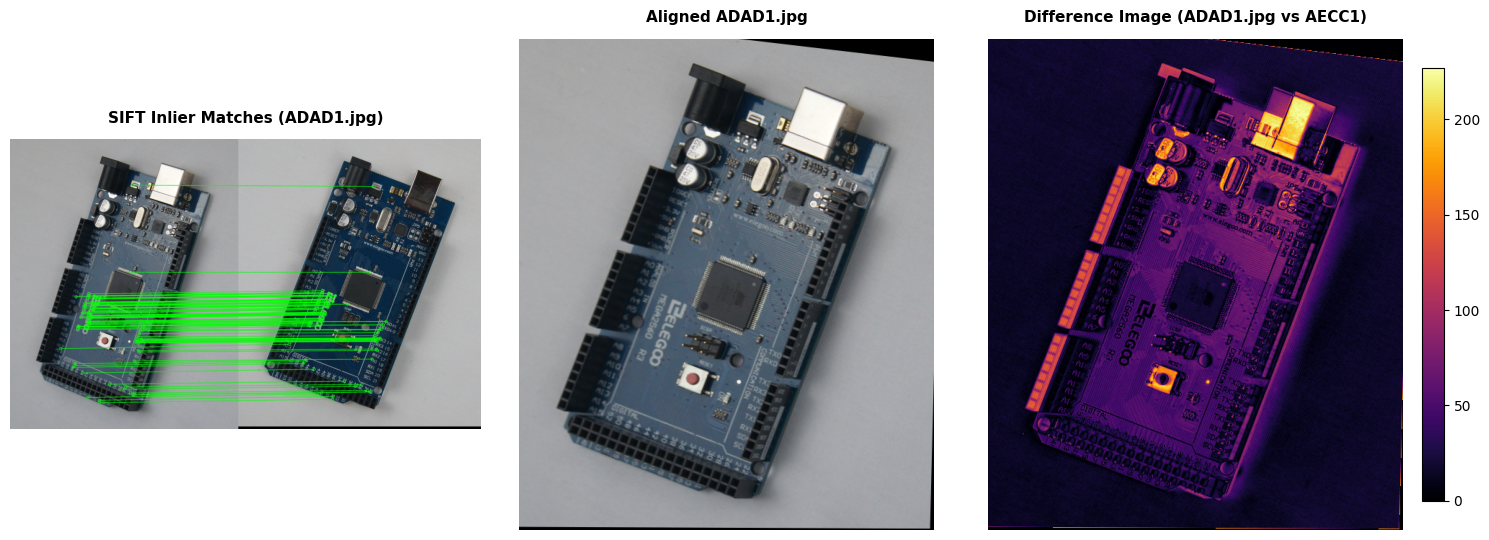

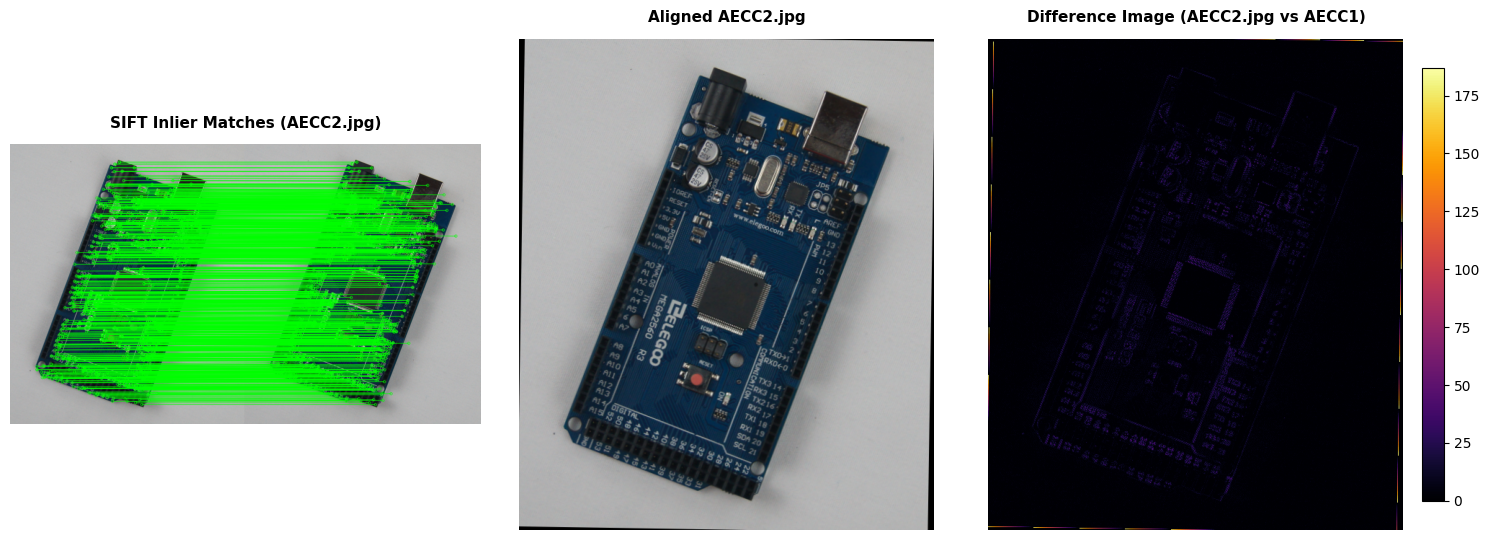

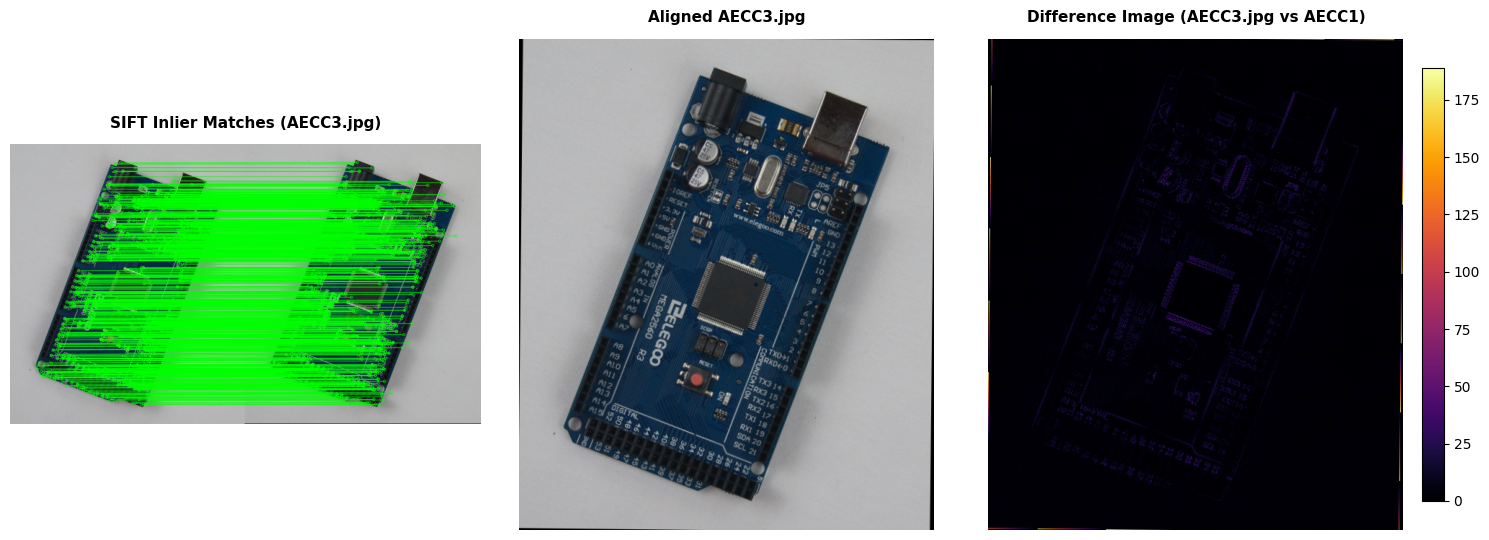

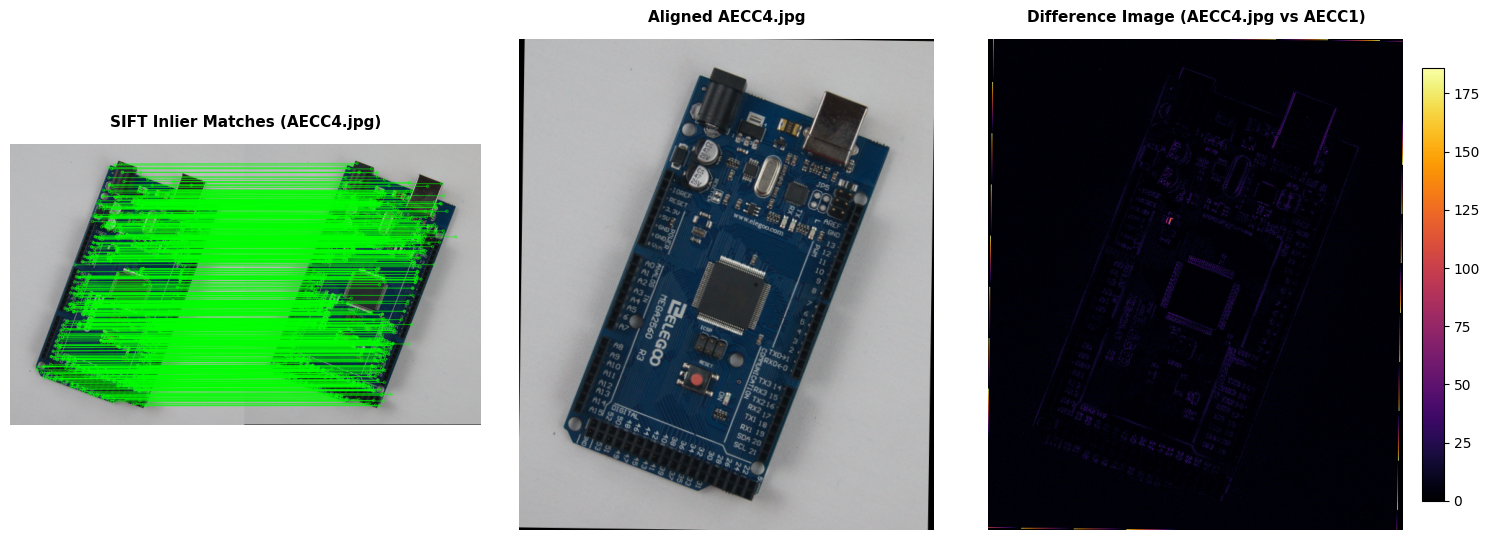

In [45]:
results = []

for name in test_names:
    path = os.path.join(IMAGE_DIR, name)
    img_bgr_raw = cv.imread(path)
    if img_bgr_raw is None:
        print(f"Skipping {name}: not found at {path}")
        continue
    
    clean_name = os.path.basename(name)
    # Downscale test image using the same scale factor
    img_bgr = cv.resize(img_bgr_raw, None, fx=SCALE, fy=SCALE, interpolation=cv.INTER_AREA)
        
    res = align_and_inspect_pcb(img_bgr, clean_name)
    results.append(res)
    
    # Mask out black warped borders so only board differences are shown
    board_mask = (cv.cvtColor(res['aligned_bgr'], cv.COLOR_BGR2GRAY) > 0) & (template_gray > 0)
    clean_diff = res['diff_gray'].copy()
    clean_diff[~board_mask] = 0

    fig, axes = plt.subplots(1, 3, figsize=(15, 5.5))
  
    axes[0].imshow(cv.cvtColor(res['match_img'], cv.COLOR_BGR2RGB))
    axes[0].set_title(f"SIFT Inlier Matches ({clean_name})", fontsize=11, fontweight='bold', pad=12)
    axes[0].axis('off')

    axes[1].imshow(cv.cvtColor(res['aligned_bgr'], cv.COLOR_BGR2RGB))
    axes[1].set_title(f"Aligned {clean_name}", fontsize=11, fontweight='bold', pad=12)
    axes[1].axis('off')

    im_diff = axes[2].imshow(clean_diff, cmap='inferno')
    axes[2].set_title(f"Difference Image ({clean_name} vs AECC1)", fontsize=11, fontweight='bold', pad=12)
    axes[2].axis('off')
    
    plt.colorbar(im_diff, ax=axes[2], fraction=0.046, pad=0.04)
    plt.subplots_adjust(top=0.85, wspace=0.15)
    plt.tight_layout()
    plt.show()

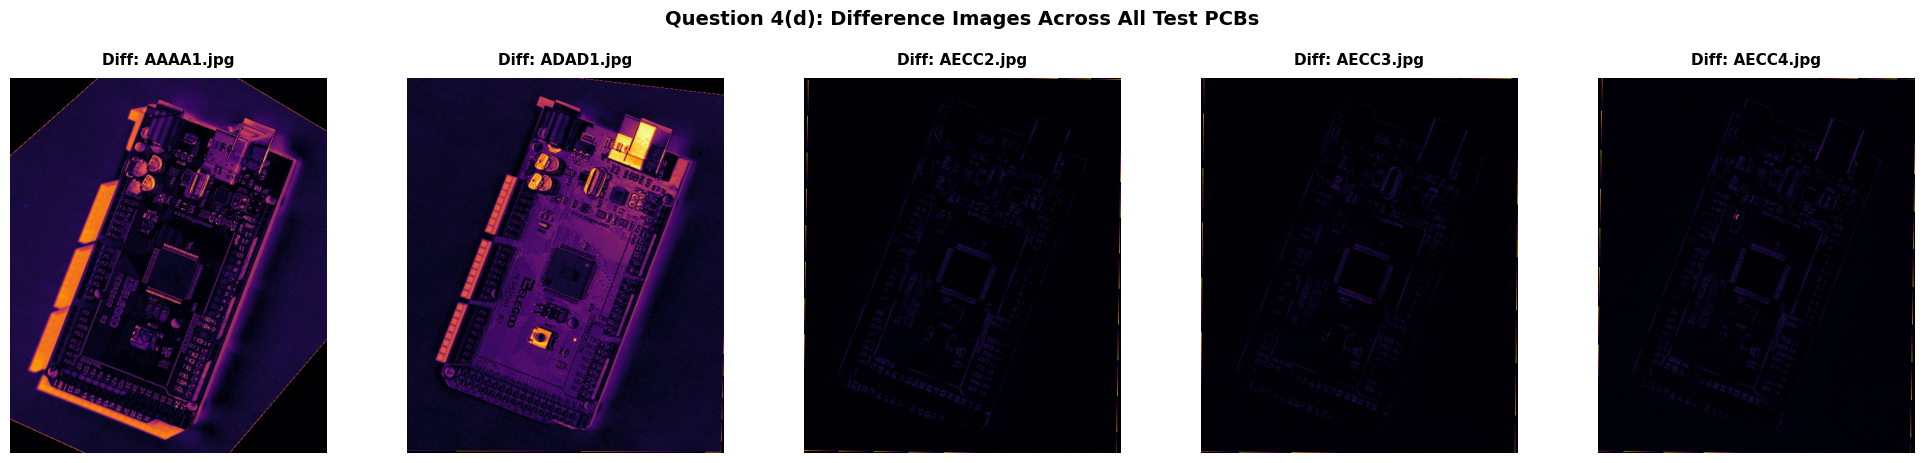

In [46]:
fig, axes = plt.subplots(1, len(results), figsize=(4 * len(results), 4.5))

for i, res in enumerate(results):
    clean_name = res['name']
    board_mask = (cv.cvtColor(res['aligned_bgr'], cv.COLOR_BGR2GRAY) > 0) & (template_gray > 0)
    clean_diff = res['diff_gray'].copy()
    clean_diff[~board_mask] = 0
    
    axes[i].imshow(clean_diff, cmap='inferno')
    axes[i].set_title(f"Diff: {clean_name}", fontsize=11, fontweight='bold', pad=10)
    axes[i].axis('off')

plt.suptitle("Question 4(d): Difference Images Across All Test PCBs", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

(d)
* The difference maps show near-zero error across the flat substrate and ICs.  
*  Boards AECC2, AECC3, and AECC4 achieve near-ideal registration, showing only faint residual outlines around through-hole pins.   
* But AAAA1 and ADAD1 display prominent localized residuals at the USB port, electrolytic capacitors, and header strips.

### Discussion  
* IFT and RANSAC did a solid job registering the test boards onto the template by finding plenty of matching copper traces and solder pads.   
* Once warped, the flat printed circuit boards aligned almost seamlessly, leaving the flat surfaces mostly dark in the difference maps.   
* However, components like the USB port, tall capacitors, and the reset button glow brightly with high error.   
* This happens because homography assumes everything is on a single flat 2D plane. But the parts we used stick out into 3D space. So it cause perspective parallax and shifting shadows when the camera angle changes.   
* Also glossy metal surfaces reflect light differently from different viewpoints.